<a href="https://colab.research.google.com/github/sumin031130/ESAA/blob/main/YB_1127_%E1%84%8B%E1%85%A7%E1%86%AB%E1%84%89%E1%85%B3%E1%86%B8%E1%84%86%E1%85%AE%E1%86%AB%E1%84%8C%E1%85%A6_%E1%84%8E%E1%85%A1%E1%84%8B%E1%85%AF%E1%86%AB%E1%84%8E%E1%85%AE%E1%86%A8%E1%84%89%E1%85%A9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 데이터 로드
from sklearn.datasets import fetch_openml
mnist=fetch_openml('mnist_784', version=1)

In [2]:
# train, test split
X_train = mnist['data'][:60000]
y_train = mnist['target'][:60000]
X_test = mnist['data'][60000:]
y_test = mnist['target'][60000:]

* 랜덤포레스트에 적용

In [3]:
# 랜덤포레스트에 적용 (n_estimators=10, random_state=42)
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=10, random_state=42)
rf_clf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=10, random_state=42)

In [18]:
# 정확도 결과
from sklearn.metrics import accuracy_score

pred = rf_clf.predict(X_test)
accuracy_score(y_test, pred)


0.9492

# 1. PCA

* PCA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [5]:
# PCA 라이브러리 불러오기
from sklearn.decomposition import PCA

In [6]:
# PCA 적용 95% : n_components=0.95
pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)
print('원본 차원:', X_train.shape[1], '→ PCA 후 차원:', pca.n_components_)   # 784 → 154

원본 차원: 784 → PCA 후 차원: 154


In [7]:
# PCA 이후 랜덤포레스트 훈련
rf_clf_pca = RandomForestClassifier(n_estimators=10, random_state=42)
rf_clf_pca.fit(X_train_reduced, y_train)

RandomForestClassifier(n_estimators=10, random_state=42)

In [8]:
# 정확도 결과 (X_test도 PCA 적용해야합니다.)
X_test_reduced = pca.transform(X_test)      # test는 fit 말고 transform만
pred_pca = rf_clf_pca.predict(X_test_reduced)
accuracy_score(y_test, pred_pca)      # 0.8915

0.8925

**관련 문제**

* PCA모델을 와인 데이터셋에 적용하여 차원을 축소하고 그 결과를 그래프로 나타내보세요.

(1) 필요한 모듈 불러오기

In [9]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

(2)  load_wine을 사용해 데이터셋을 생성한다.

In [10]:
wine = load_wine()
X = wine.data
y = wine.target

(3) X에 표준 스케일링(Standard scaling)을 적용하여 X_scaled을 생성한다.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

(4) PCA 모델을 X에 적용하여 2개의 차원으로 추출한다. 단, random_state=1234로 설정한다.

In [12]:
#PCA 모델을 X_scaled에 적용하여 2개의 차원으로 추출한다.
pca_wine = PCA(n_components=2, random_state=1234)
X_pca = pca_wine.fit_transform(X_scaled)
print(pca_wine.explained_variance_ratio_)




[0.36198848 0.1920749 ]


(5) 추출한 피처를 그래프로 나타내라.

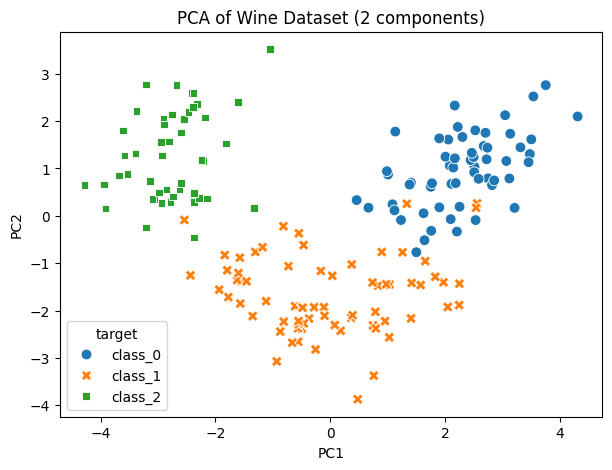

In [13]:
wine_pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
wine_pca_df['target'] = wine.target_names[y]

plt.figure(figsize=(7, 5))
sns.scatterplot(data=wine_pca_df, x='PC1', y='PC2', hue='target', style='target', s=60)
plt.title('PCA of Wine Dataset (2 components)')
plt.show()

# 2. LDA

- LDA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [14]:
# LDA 라이브러리 불러오기
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [15]:
# LDA 적용 : n_components=5
lda = LinearDiscriminantAnalysis(n_components=5)
X_train_lda = lda.fit_transform(X_train, y_train)

In [16]:
# LDA 이후 랜덤포레스트 훈련
rf_clf_lda = RandomForestClassifier(n_estimators=10, random_state=42)
rf_clf_lda.fit(X_train_lda, y_train)

RandomForestClassifier(n_estimators=10, random_state=42)

In [17]:
# 정확도 결과 (X_test도 LDA 적용해야합니다.)
X_test_lda = lda.transform(X_test)
pred_lda = rf_clf_lda.predict(X_test_lda)
accuracy_score(y_test, pred_lda)

0.8301